# TRAFFIC VOLUME PREDICTION ANALYSIS

### Time-series analysis using a Random Forest Regressor


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data=pd.read_csv("traffic.csv")
data.head()

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DateTime  48120 non-null  object
 1   Junction  48120 non-null  int64 
 2   Vehicles  48120 non-null  int64 
 3   ID        48120 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [4]:
data['DateTime']=pd.to_datetime(data['DateTime'])
data=data.drop(['ID'],axis=1)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   DateTime  48120 non-null  datetime64[ns]
 1   Junction  48120 non-null  int64         
 2   Vehicles  48120 non-null  int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 1.1 MB


In [5]:
df=data.copy()

Text(0, 0.5, 'Number of Vehicles')

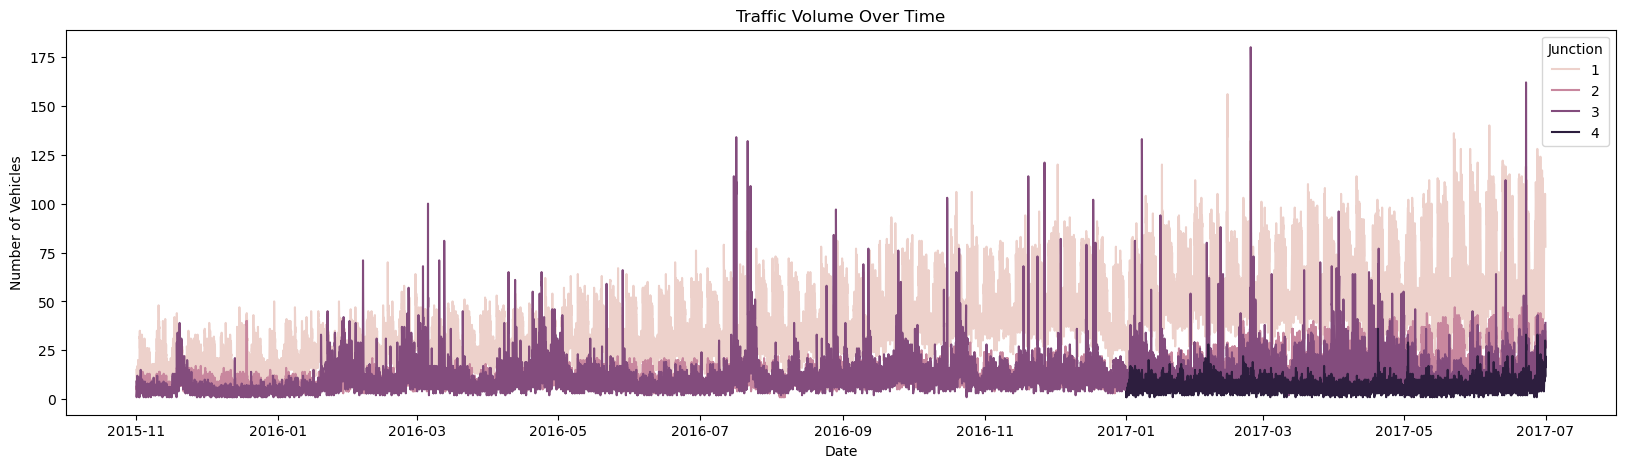

In [6]:
plt.figure(figsize=(20,5))
time_series=sns.lineplot(x=df['DateTime'],y=df['Vehicles'],data=df,hue=df['Junction'])
time_series.set_title('Traffic Volume Over Time')
time_series.set_xlabel('Date')
time_series.set_ylabel('Number of Vehicles')

In [7]:
df['Year']=df['DateTime'].dt.year
df['Month']=df['DateTime'].dt.month
df['Date_no']=df['DateTime'].dt.day
df['Hour']=df['DateTime'].dt.hour
df['day_of_week']=df['DateTime'].dt.dayofweek+1
df.head()

,DateTime,Junction,Vehicles,Year,Month,Date_no,Hour,day_of_week
0,2015-11-01 00:00:00,1,15,2015,11,1,0,7
1,2015-11-01 01:00:00,1,13,2015,11,1,1,7
2,2015-11-01 02:00:00,1,10,2015,11,1,2,7
3,2015-11-01 03:00:00,1,7,2015,11,1,3,7
4,2015-11-01 04:00:00,1,9,2015,11,1,4,7


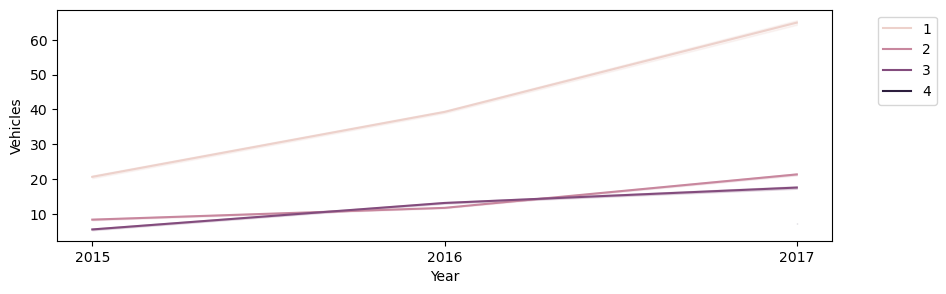

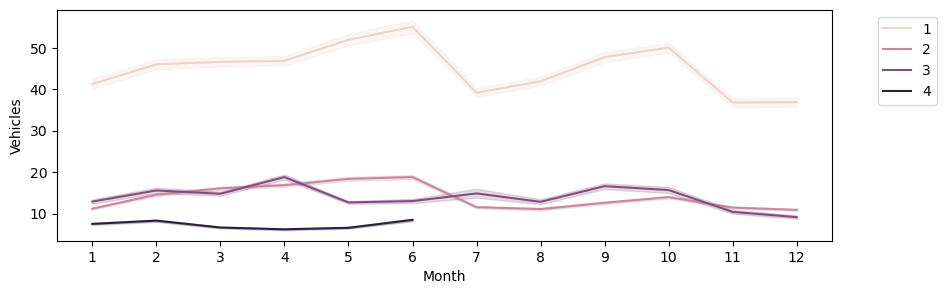

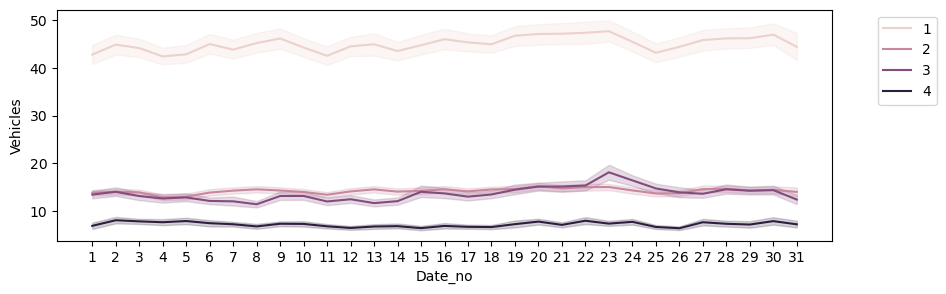

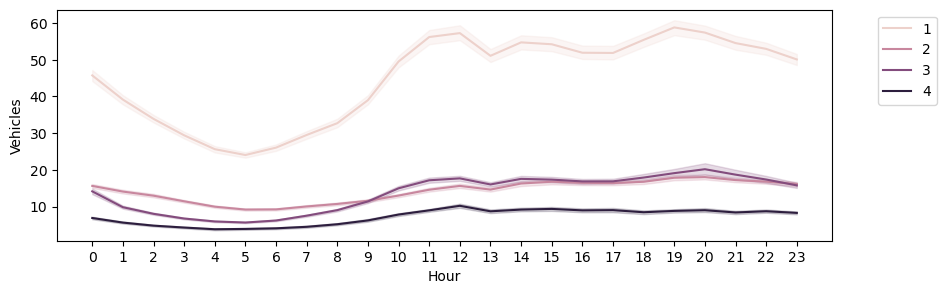

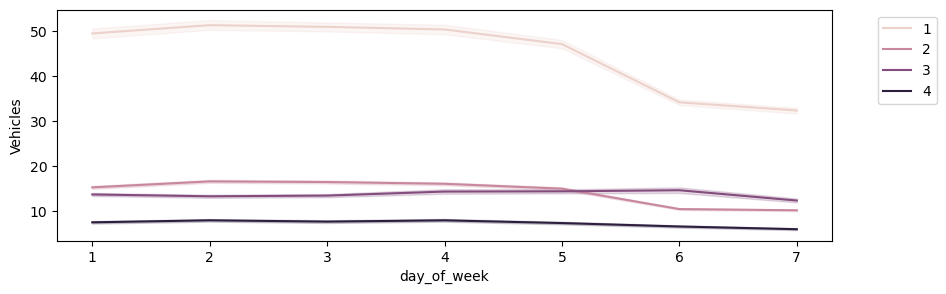

In [8]:
features=['Year','Month','Date_no','Hour','day_of_week']

for i in features:
    plt.figure(figsize=(10,3))
    ax=sns.lineplot(x=df[i],y=df['Vehicles'],data=df,hue="Junction")
    x_ticks = sorted(df[i].unique())
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticks)
    plt.legend(bbox_to_anchor=(1.05, 1), loc=2)

Text(0, 0.5, 'Number of Vehicles')

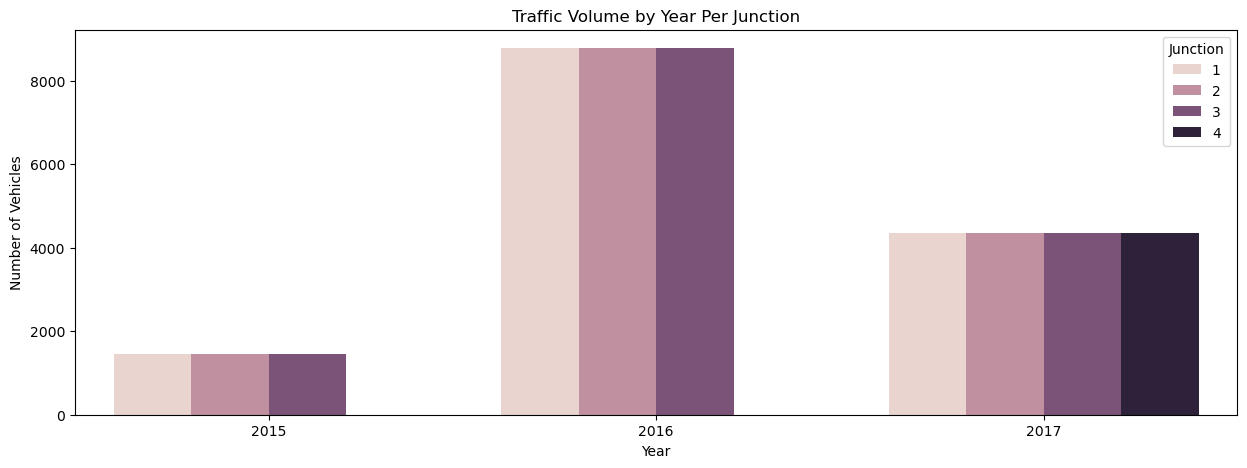

In [9]:
plt.figure(figsize=(15,5))
count=sns.countplot(data=df,x='Year',hue='Junction')
count.set_title('Traffic Volume by Year Per Junction')
count.set_xlabel('Year') 
count.set_ylabel('Number of Vehicles')  

In [10]:
df_J=data.pivot(columns='Junction',index='DateTime')
df_J.describe()

Vehicles                                         
Junction             1             2             3            4
count     14592.000000  14592.000000  14592.000000  4344.000000
mean         45.052906     14.253221     13.694010     7.251611
std          23.008345      7.401307     10.436005     3.521455
min           5.000000      1.000000      1.000000     1.000000
25%          27.000000      9.000000      7.000000     5.000000
50%          40.000000     13.000000     11.000000     7.000000
75%          59.000000     17.000000     18.000000     9.000000
max         156.000000     48.000000    180.000000    36.000000

## Random Forest Regressor

Since the task is prediction of a continuous quantity,
Random Forest Regressor can learn nonlinear relationships between time-based features and traffic volume.

In [11]:
df = pd.read_csv('traffic.csv')
df = df.set_index('DateTime')
df.index = pd.to_datetime(df.index)
df.head()

,Junction,Vehicles,ID
DateTime,,,
2015-11-01 00:00:00,1,15,20151101001
2015-11-01 01:00:00,1,13,20151101011
2015-11-01 02:00:00,1,10,20151101021
2015-11-01 03:00:00,1,7,20151101031
2015-11-01 04:00:00,1,9,20151101041


### Vehicles over times plot

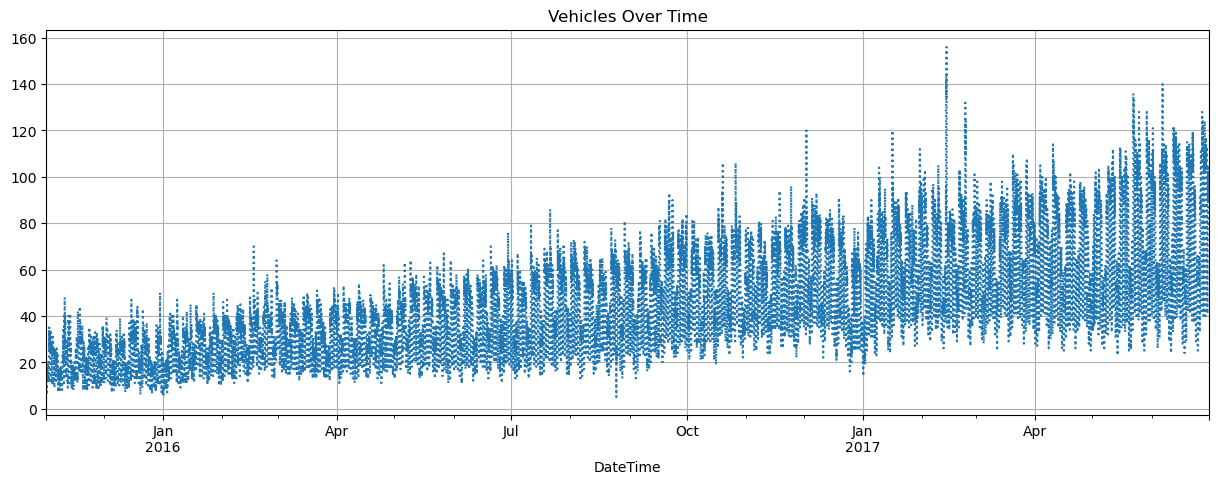

In [12]:
junction_1_data = df[df['Junction']==1] # Vehicles volume in Junction 1
junction_1_data['Vehicles'].plot(linestyle='dotted',
        figsize=(15, 5),
        title='Vehicles Over Time')
plt.grid()
plt.show()

### Vehicles Frequency plot


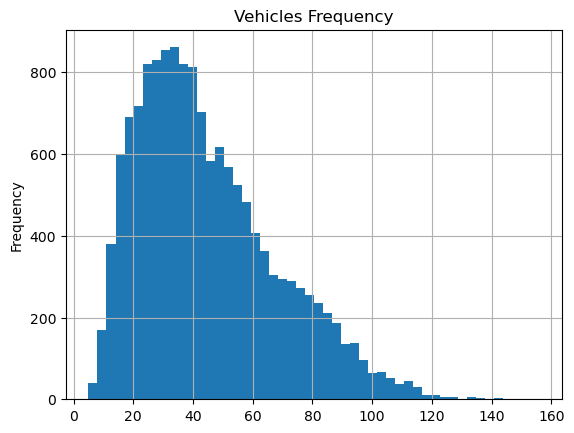

In [13]:
junction_1_data['Vehicles'].plot(kind='hist', bins=50, title='Vehicles Frequency')
plt.grid()
plt.show()

## Time Series Cross Validation

In [14]:
from sklearn.model_selection import TimeSeriesSplit

tss = TimeSeriesSplit(n_splits=3, test_size=24*120*1, gap=24)
junction_1_data = junction_1_data.sort_index()

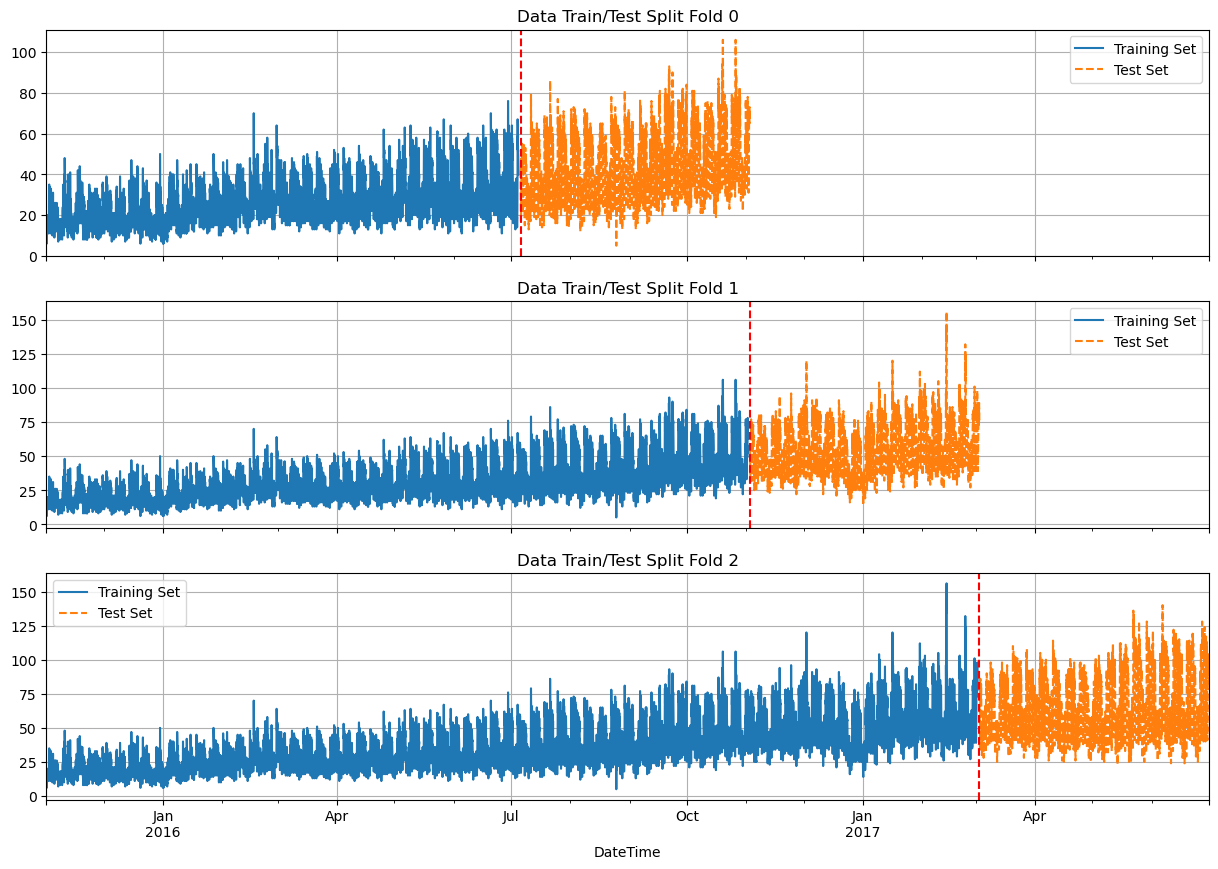

In [15]:
fig, axs = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

fold = 0
for train_idx, val_idx in tss.split(junction_1_data):
    train = junction_1_data.iloc[train_idx]
    test = junction_1_data.iloc[val_idx]
    train['Vehicles'].plot(ax=axs[fold],
                          label='Training Set',
                          title=f'Data Train/Test Split Fold {fold}', 
                          linestyle='-')
    test['Vehicles'].plot(ax=axs[fold],
                         label='Test Set', 
                         linestyle='--')
    axs[fold].axvline(test.index.min(), color='red', ls='--')
    axs[fold].grid(True) 
    axs[fold].legend()    
    fold += 1
plt.show()

### Week of data plot
This plot is useful for observing:

- Daily peaks.
- Nighttime reductions.
- Differences between weekdays and weekends.
- Repeating hourly patterns.

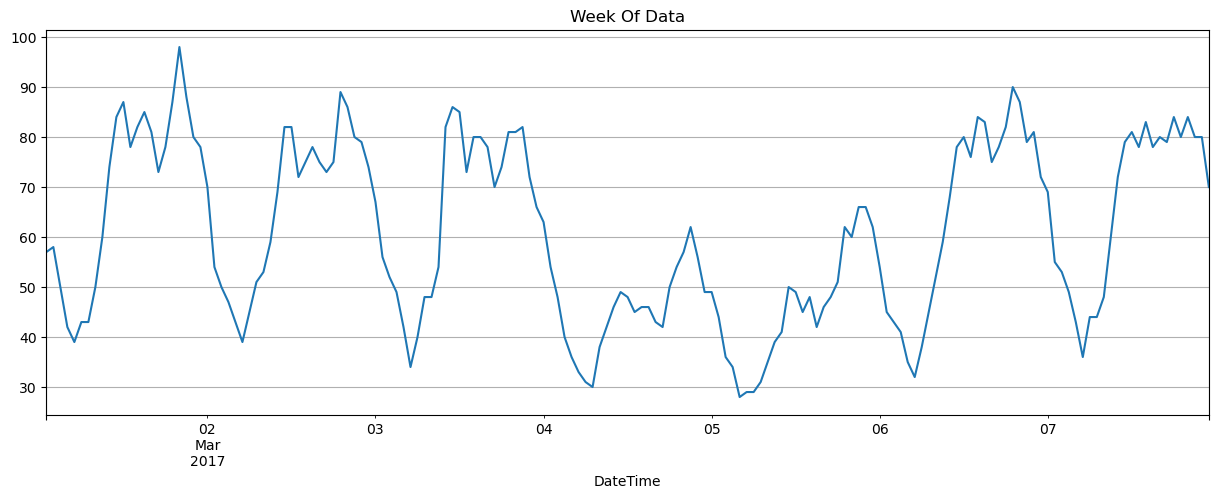

In [16]:
junction_1_data['Vehicles'].loc[(junction_1_data.index > '03-01-2017') & (junction_1_data.index < '03-08-2017')] \
    .plot(figsize=(15, 5), title='Week Of Data')
plt.grid()
plt.show()

### Feature Creation

In [17]:
def create_features(junction_1_data):
    """
    Create time series features based on time series index.
    """
    junction_1_data = junction_1_data.copy()
    junction_1_data['hour'] = junction_1_data.index.hour
    junction_1_data['dayofweek'] = junction_1_data.index.dayofweek
    junction_1_data['quarter'] = junction_1_data.index.quarter
    junction_1_data['month'] = junction_1_data.index.month
    junction_1_data['year'] = junction_1_data.index.year
    junction_1_data['dayofyear'] = junction_1_data.index.dayofyear
    junction_1_data['dayofmonth'] = junction_1_data.index.day
    junction_1_data['weekofyear'] = junction_1_data.index.isocalendar().week
    return junction_1_data

junction_1_data = create_features(junction_1_data)

### Model Training

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error


tss = TimeSeriesSplit(n_splits=3, test_size=24*120*1, gap=24)
junction_1_data = junction_1_data.sort_index()

fold = 0
preds = []
scores = []

for train_idx, val_idx in tss.split(junction_1_data):
    train = junction_1_data.iloc[train_idx]
    test = junction_1_data.iloc[val_idx]

    train = create_features(train)
    test = create_features(test)

    FEATURES = ['hour', 'dayofweek', 'month', 'year', 'dayofyear', 'dayofmonth', 'weekofyear']
    TARGET = 'Vehicles'

    X_train = train[FEATURES]
    y_train = train[TARGET]

    X_test = test[FEATURES]
    y_test = test[TARGET]

    reg = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1 #Uses all available CPU cores to train the forest faster.
    )

    reg.fit(X_train, y_train)

    y_pred = reg.predict(X_test)
    preds.append(y_pred)
    score = np.sqrt(mean_squared_error(y_test, y_pred))
    scores.append(score)

In [19]:
print(f'Score across folds {np.mean(scores):0.4f}')
print(f'Fold scores:{scores}')

Score across folds 23.1920
Fold scores:[np.float64(23.02087474744124), np.float64(35.40844193820997), np.float64(11.146753506841325)]


### Hyperparameter tuning with GridSearchCV

In [20]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor

FEATURES = [
    'hour', 'dayofweek', 'month', 'year',
    'dayofyear', 'dayofmonth', 'weekofyear'
]
TARGET = 'Vehicles'

# Keep observations in chronological order
junction_1_data = junction_1_data.sort_index()

# Create time-based features
data = create_features(junction_1_data)

X = data[FEATURES]
y = data[TARGET]

# Reserve the final 2,880 observations for independent testing
test_size = 24 * 120

X_train = X.iloc[:-test_size]
y_train = y.iloc[:-test_size]

X_test = X.iloc[-test_size:]
y_test = y.iloc[-test_size:]

# Perform cross-validation only on the training period
tss = TimeSeriesSplit(
    n_splits=3,
    test_size=24 * 120,
    gap=24
)

reg = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [100, 500, 1000],
    'max_depth': [5, 10, 15]
}

grid_search = GridSearchCV(
    estimator=reg,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tss,
    verbose=1,
    n_jobs=-1
)

# Fit and tune using training data only
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("CV RMSE:", -grid_search.best_score_)

# This estimator has been refitted on X_train, y_train only
best_model = grid_search.best_estimator_

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best parameters: {'max_depth': 5, 'n_estimators': 100}
CV RMSE: 21.593404430391775


Scikit-learn's model-selection API assumes that larger scores are better. Since lower RMSE is better, scikit-learn stores RMSE as a negative number: -4.0 is greater than -6.0, so the lower RMSE is selected.

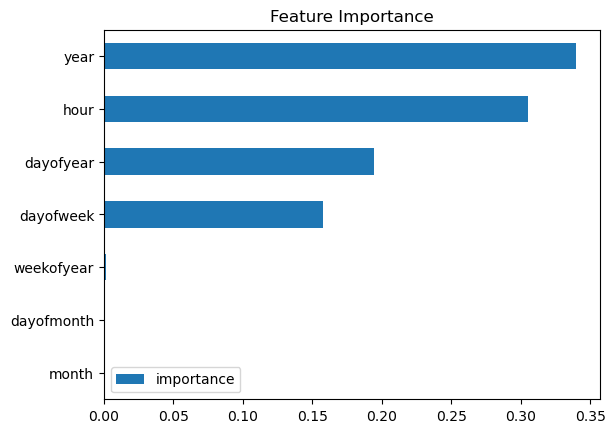

In [21]:
fi = pd.DataFrame(data=best_model.feature_importances_,
             index=best_model.feature_names_in_,
             columns=['importance'])
fi.sort_values('importance').plot(kind='barh', title='Feature Importance')
plt.show()

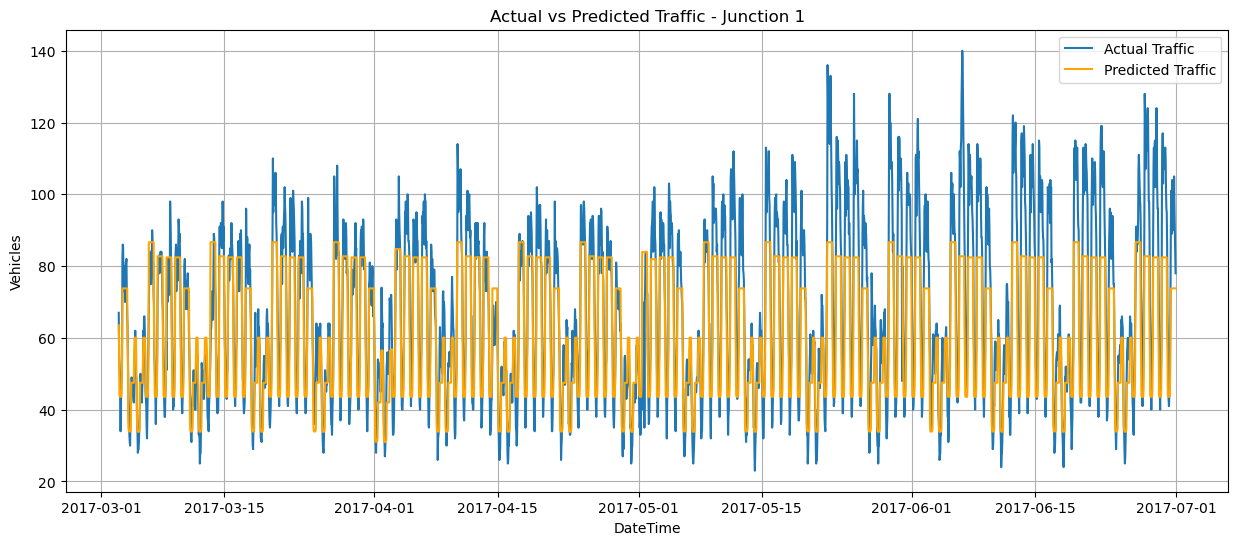

In [22]:
# Predict on the independent test dataset
y_pred = best_model.predict(X_test)

test_results = junction_1_data.iloc[-test_size:].copy()
test_results['prediction'] = y_pred

plt.figure(figsize=(15, 6))

plt.plot(
    test_results.index,
    test_results['Vehicles'],
    label='Actual Traffic'
)

plt.plot(
    test_results.index,
    test_results['prediction'],
    label='Predicted Traffic',
    color='orange'
)

plt.title('Actual vs Predicted Traffic - Junction 1')
plt.xlabel('DateTime')
plt.ylabel('Vehicles')
plt.legend()
plt.grid()
plt.show()

### Forecast on Test

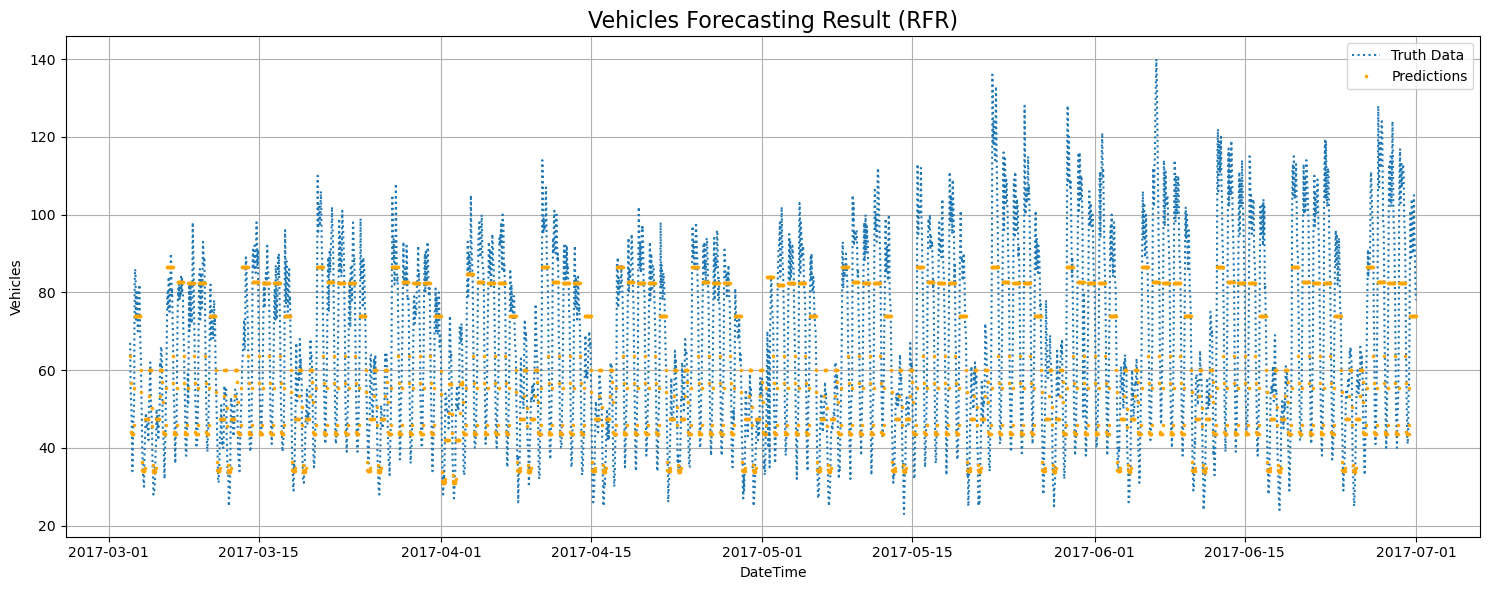

In [23]:
import matplotlib.dates as mdates

# Forecast on the independent test period
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    test_results.index,
    test_results['Vehicles'],
    label='Truth Data',
    linestyle='dotted'
)
ax.plot(
    test_results.index,
    test_results['prediction'],
    label='Predictions',
    linestyle='None',
    marker='.',
    color='orange',
    markersize=3
)

ax.set_title('Vehicles Forecasting Result (RFR)', fontsize=16)
ax.set_xlabel('DateTime')
ax.set_ylabel('Vehicles')
ax.grid(True)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

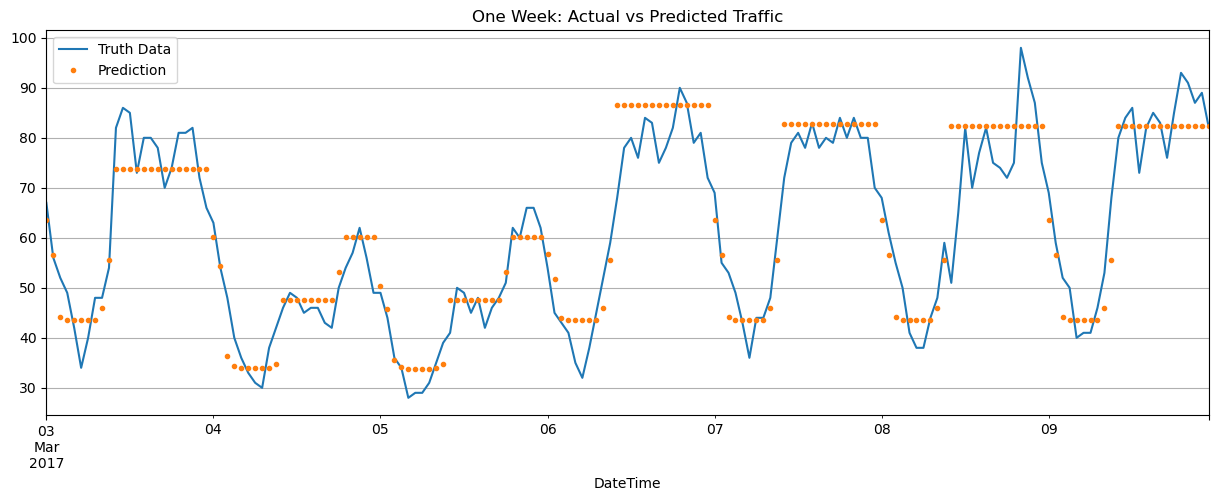

In [24]:
# Compare actual and predicted traffic for the first week of the test period
week_start = test_results.index.min()
week_end = week_start + pd.Timedelta(days=7)

week_results = test_results.loc[
    (test_results.index >= week_start) &
    (test_results.index < week_end)
]

ax = week_results['Vehicles'].plot(
    figsize=(15, 5),
    title='One Week: Actual vs Predicted Traffic'
)
week_results['prediction'].plot(style='.', ax=ax)

plt.legend(['Truth Data', 'Prediction'])
plt.grid()
plt.show()

In [25]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evaluate predictions on the independent test dataset
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

MAE: 8.6554
MSE: 137.5479
RMSE: 11.7281
R² Score: 0.7553


### Calculate Error

In [26]:
test_results['error'] = np.abs(
    test_results['Vehicles'] - test_results['prediction']
)
test_results['date'] = test_results.index.date

result = (
    test_results.groupby('date')['error']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

result_df = pd.DataFrame(result).reset_index()
result_df.columns = ['Date', 'Mean Error']
result_df

,Date,Mean Error
0,2017-06-27,22.977477
1,2017-06-06,22.485820
2,2017-05-22,20.465228
3,2017-06-29,18.978535
4,2017-06-28,18.728535
5,2017-06-13,18.427468
6,2017-06-07,17.886860
7,2017-06-20,17.152487
8,2017-05-23,17.102477
9,2017-05-25,16.995220


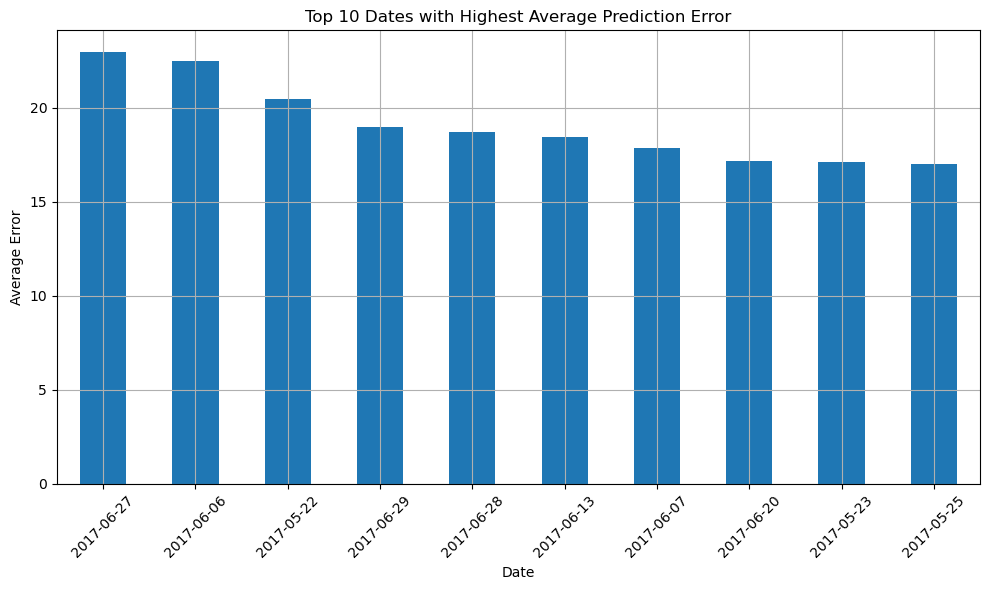

In [27]:
plt.figure(figsize=(10, 6))
result.plot(kind='bar')
plt.title('Top 10 Dates with Highest Average Prediction Error')
plt.xlabel('Date')
plt.ylabel('Average Error')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.show()

In [28]:
# Find the last available timestamp used 
# as the starting point for creating future timestamps.
junction_1_data.index.max()

Timestamp('2017-06-30 23:00:00')

In [29]:
# Create future hourly timestamps after the last historical observation
future = pd.date_range(
    start=junction_1_data.index.max() + pd.Timedelta(hours=1),
    end='2017-08-01',
    freq='h'
)

future_junction_1_data = pd.DataFrame(index=future)
future_junction_1_data['isFuture'] = True

# Mark historical observations and combine them with future timestamps
junction_1_data['isFuture'] = False
df_and_future_1 = pd.concat([
    junction_1_data,
    future_junction_1_data
]).sort_index()

# Generate calendar features for historical and future timestamps
df_and_future_1 = create_features(df_and_future_1)

### Predict the future

In [30]:
# Retrain the selected model using all available historical data
final_model = RandomForestRegressor(
    **grid_search.best_params_,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [31]:
# Select future observations for forecasting
future_w_features_1 = df_and_future_1.query('isFuture').copy()

In [32]:
# Generate future traffic predictions
future_w_features_1['pred'] = final_model.predict(
    future_w_features_1[FEATURES]
)

c:\ProgramData\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


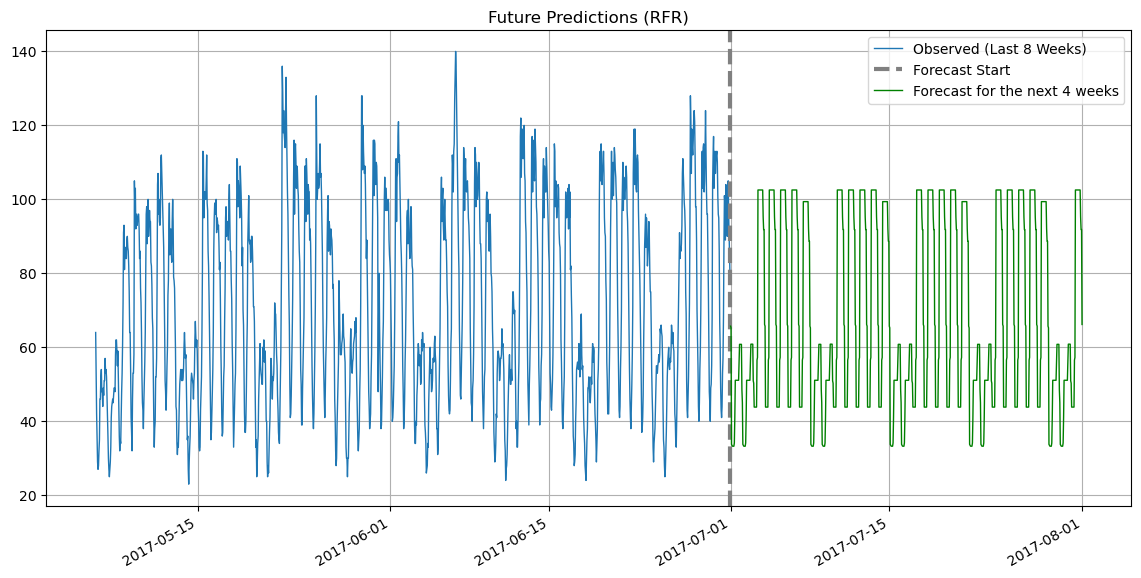

In [33]:
plt.plot(junction_1_data['Vehicles'][-24*7*8:], 
         label='Observed (Last 8 Weeks)', 
         ms=1, 
         lw=1)
plt.axvline(x=junction_1_data.index.max(), 
            color='gray', 
            linestyle='--', 
            label='Forecast Start', 
            ms=1,
            lw=3)
future_w_features_1['pred'].plot(figsize=(14, 7),
                               color='green',
                               ms=1,
                               lw=1,
                               title='Future Predictions (RFR)', 
                               label='Forecast for the next 4 weeks')
plt.legend()
plt.grid()
plt.show()


## Conclusion

This project demonstrated the use of a Random Forest Regressor for traffic volume prediction and future forecasting using historical traffic data. The workflow included data preprocessing, exploratory data analysis, time-based feature engineering, time-series cross-validation, and hyperparameter tuning.

The model was evaluated using MAE, MSE, RMSE, and R² metrics to assess its predictive performance. The forecasting process generated estimated traffic volumes for the next four weeks at Junction 1, helping identify recurring traffic patterns.

**Limitations:** The model primarily relies on calendar-based features and does not explicitly capture sequential traffic dependencies or external factors such as weather, accidents, and road conditions. Its performance during unusual traffic fluctuations may therefore be limited.

Overall, the project demonstrates how machine learning can support traffic pattern analysis and forecasting, providing a foundation for data-driven traffic planning and management.
